# Example on How to Overplot Cluster Locations
- Showingboth Methods 1. Manual and 2. CARTA regions
-  Author: @aelieber1, @millbets

## Import Packages

In [161]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from astropy.wcs import WCS
from astropy import units as u
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.visualization.wcsaxes import add_beam, add_scalebar

from spectral_cube import SpectralCube

import astropy.io.fits as fits

# Plot formatting
%matplotlib inline
matplotlib.rc('font', family='sans-serif')
matplotlib.rc('text', usetex=False)

In [91]:
# Import your data (I'll use a cube here and make a mom0 map)

#H40alpha_processed_path = '/Users/ashleylieber/MIlls_Research/VibCubes/UniformProcessing_Feb2024/Smoothed_DataCubes/H40_Alpha_smoothed.fits'
#H40alpha_processed_cube = SpectralCube.read(H40alpha_processed_path)

#filelabel = "H40_Alpha" # How the file is labeled in my directory
#fmt_label = "H40 $a$" # Nicely formated label 

#moment0 = H40alpha_processed_cube.moment(order=0, how='slice')

# This gives us a nice 2D image (similar to how a continuum image already is)
# you might not be able to import a readymade continuum file into SpectralCube (it can yell at you when it isn't 3D), so if that is the case, you can import using fits (example below)
#cont = fits.getdata(__path__)
#ont_header = fits.getheader(dataset_dpathir)

## Method 1: Manually Input Cluster Locations and Plot

In [28]:
# Get the pixel location of our apertures
w_ref = moment0.wcs # Grab the 2D coordinate system from the moment map
# w_ref = WCS.dropaxis(w_ref, dropax=2) # if your continuum has a 3rd axis you might need to drop it
# print(w_ref) # you can check the structure by printing

xs = np.zeros((14),float) # will eventaully store the pixel locations of x coordiantes of each SSC
ys = np.zeros((14),float) # will eventaully store the pixel locations of y coordiantes of each SSC

# Locations of SSCs in NGC 253
sources = np.array(['1','2','3','4','5','6','7','8','9','10','11','12','13','14'])

# Source Right Ascensions (Mills+2021)
RAs =  np.array([11.886669,11.886749,11.886829,11.8872162,11.8874364,11.88755,\
                    11.887567,11.887978,11.887984,11.8881464,\
                    11.8882,11.888264,11.888322,11.8887287])

# Source Declinations (Mills+2021)
Decs = np.array([-25.289232,-25.289240,-25.289200,-25.2889692,-25.288806,-25.288737,\
                    -25.288628,-25.288244,-25.288389,-25.2880799,\
                    -25.288175,-25.288095,-25.287989,-25.2876482]) 

# Convert all RA and DECs to pixels
for i in np.arange(0,14):
    xs[i],ys[i] = w_ref.all_world2pix(RAs[i],Decs[i],0)

In [29]:
# In Mills+2021 and Lieber et al. (in prep) the apertures have 3pc radii, we need to calculate this in pixels
D = 3.5e6 * u.pc # Dist to NGC 253
aperture_radius = 3.0 * u.pc 

theta = (aperture_radius/D * u.rad).to(u.arcsec) # radius in angular size (Linear to angular size equation)
print(f"Angular radius: {theta:.3f}") # Radius in angular units

pixscale = abs(H40alpha_processed_cube.header['CDELT1']) * u.deg # you can grab the size of the pixel from the header; CDELT2 should be the same 
print(f"Pixel scale: {pixscale.to(u.arcsec):.2f}") # How big are our pixels 

apsize = (theta / pixscale.to(u.arcsec)).value # Calculates how many pixels you need to have a radius at the proper radius you set
print(f"Aperture radius: {apsize:.3f} pixels") 



Angular radius: 0.177 arcsec
Pixel scale: 0.03 arcsec
Aperture radius: 5.893 pixels


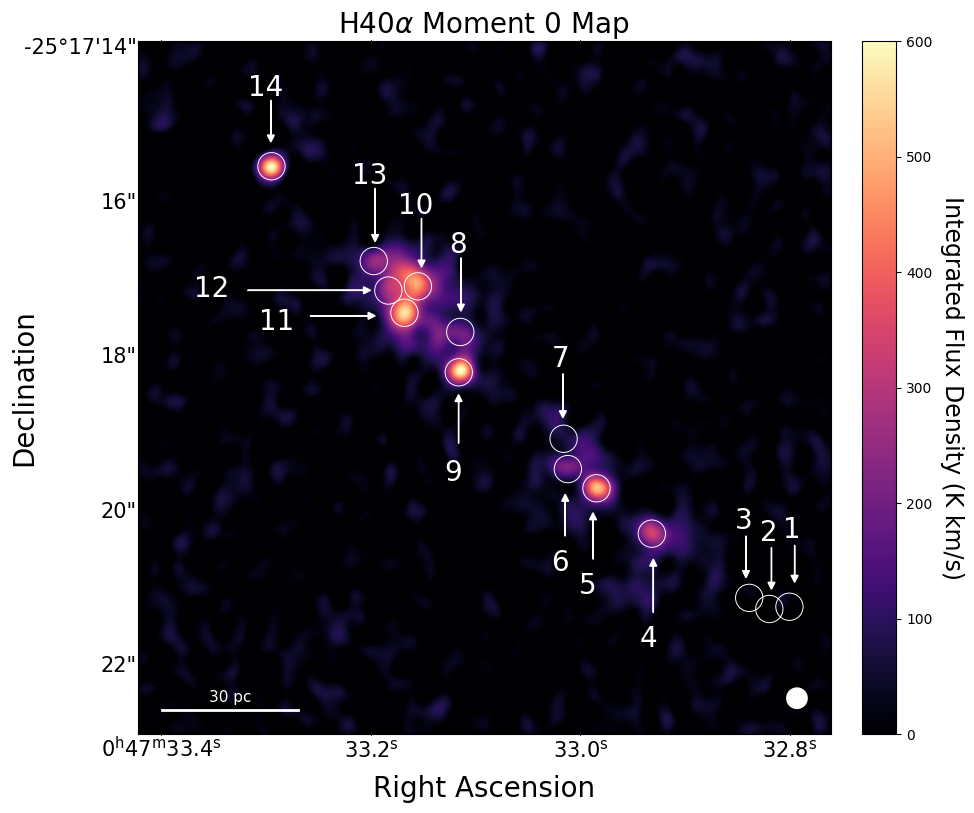

In [30]:

# Location information for arrows (if you wnat to have numbers and arrows) -- if you just want the circles, disregard
Lx  = np.array([283,273,262,222,196,184,183,139,  138,122,74,  47,102, 57])
Ly  = np.array([ 81, 80, 85, 52, 75, 85,155,205,  125,222,180, 191,235,273])
Ldx = np.array([  0,  0,  0,  0,  0,  0,  0,  0,    0,  0,  25,  50,  0,  0])
Ldy = np.array([-13,-15,-15, 20, 17, 15,-16,-20,   18, -18,  0,   0,-20,-15])
Ltx = np.array([ -5, -5, -5, -6, -6, -6, -5, -5,   -6, -10, -22, -23, -10, -10])
Lty = np.array([  3,  3,  3,-15,-15,-15,  3,  2,    -16, 2,  -6,-3,  2,  2])

# Plotting
fig = plt.figure(1,figsize=(10,9))

ax = plt.subplot(1,1,1,projection=moment0.wcs) 
im = ax.imshow(moment0.hdu.data,cmap='magma',origin='lower',vmin=0,vmax=600)

ax.set_title(r'H40$\alpha$ Moment 0 Map', fontsize=20)

RA = ax.coords[0]                                                                  
Dec = ax.coords[1]
RA.set_ticks(size=1)                                                                                      
Dec.set_ticks(size=-3)     

plt.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
plt.ylabel('Declination',fontsize=20,labelpad=0)

ax.tick_params(axis = 'both', which = 'major', labelsize = 15)  
 
cb = fig.colorbar(im, ax=ax, fraction=0.046,pad=0.04)                                      
cb.set_label(label='Integrated Flux Density (K km/s)',fontsize=17,rotation=270,labelpad=23) 
cb.ax.tick_params(which = 'major', labelsize = 10) 

########################### this is the aperture plotting that is important!! ###########################

for i,x in enumerate(xs):
    ax.add_patch(matplotlib.patches.Circle((x,ys[i]),apsize,fill=False,lw=0.7,edgecolor='white',zorder=5)) #uses the apsize you defined to set the radius


############################################################################################################

for i,x in enumerate(Lx):
    ax.arrow(x,Ly[i], Ldx[i], Ldy[i],width=0.1,head_width=3,head_length=3,color='white')
    ax.text(x+Ltx[i],Ly[i]+Lty[i],sources[i],fontsize=20,color='white')

############################################################################################################

# Add 30 pc scale bar
D = 3.5e6 * u.pc
L = 30 * u.pc
theta = (L / D) * u.rad
theta_arcsec = theta.to(u.arcsec)
pixscale = abs(H40alpha_processed_cube.header['CDELT1']) * u.deg
bar_length_pix = (theta_arcsec / pixscale.to(u.arcsec)).value
ax.plot([10, 10 + bar_length_pix],[10, 10],color='white',lw=2)
ax.text(10 + bar_length_pix / 2,12,"30 pc",color='white',ha='center',va='bottom',fontsize=11)

# Add Beam
beam_radius_pix = (H40alpha_processed_cube.header['BMAJ'] / abs(H40alpha_processed_cube.header['CDELT1'])) / 2.0
ny, nx = moment0.shape
beam_x = nx - 15
beam_y = 15
ax.add_patch(matplotlib.patches.Circle((beam_x, beam_y),beam_radius_pix,fill=True,lw=1.2,fc='white',ec='white')) 

plt.show()


## Method 2: CARTA Region File

In [166]:
# You'll need this package
import regions
from regions import Regions
from regions import PixCoord
from regions import RectangleSkyRegion, RectanglePixelRegion

import pylab

# Load the CARTA region file
region_path = "/Users/mills-group/Downloads/regions-notebook/H40a_region"
H40a_region = Regions.read(region_path, format="crtf")
print(f"Loaded {len(H40a_crop)} aperture")

H40a_path = '/Users/mills-group/Downloads/regions-notebook/NGC253_H40a_2016.1.00481.c.S.fits'
H40a_cube = SpectralCube.read(H40a_path)

filelabel = "NGC253_H40a"
fmt_label = "H40 $a$"

H40a_crop = H40a_cube.subcube_from_regions(H40a_region)
H40a_crop.hdu.writeto('NGC253_H40a_2016.1.00481.c.S.fits', overwrite=True)

H40a_crop_cube = SpectralCube.read(H40a_path)

moment0 = H40a_crop_cube.moment(order=0, how='slice')
imgshape = np.shape(moment0)
print(imgshape)
#region_H40a = RectanglePixelRegion(center=PixCoord(x=1270,y=1287),width=300,height=264, angle=0*u.deg)
#crop_H40a = H40a_cube.subcube_from_regions(region_H40a)


Loaded 41 aperture
(265, 300)


In [177]:
image = fits.getdata(H40a_path)
header = fits.getheader(H40a_path)
mJy_image = image *1000
header['BUNIT'] = 'mJy/beam'
w1 = WCS(header)
#w1 = w1.dropaxis(3)
w1 = w1.dropaxis(2)
image_2d = pylab.squeeze(image)
ra, dec = w1.all_pix2world(1285,1277,0)
print(ra,dec)

region_str = "circle[[11.87475deg, -25.27619deg], 0.8deg], coord=fk5" 
region = regions.Regions.parse(region_str,format='crtf')
crop = H40a_cube.subcube_from_regions(region) 
moment0 = crop.moment(order=0, how='slice')

11.87475229261722 -25.276191084204182


In [170]:
# You'll need this package
from regions import Regions

import pylab

# Load the CARTA region file
region_path = "/Users/mills-group/Downloads/regions-notebook/SSC_Location_Mills2021_3pc.crtf"
apertures = Regions.read(region_path, format="crtf")
print(f"Loaded {len(apertures)} apertures")

Loaded 14 apertures


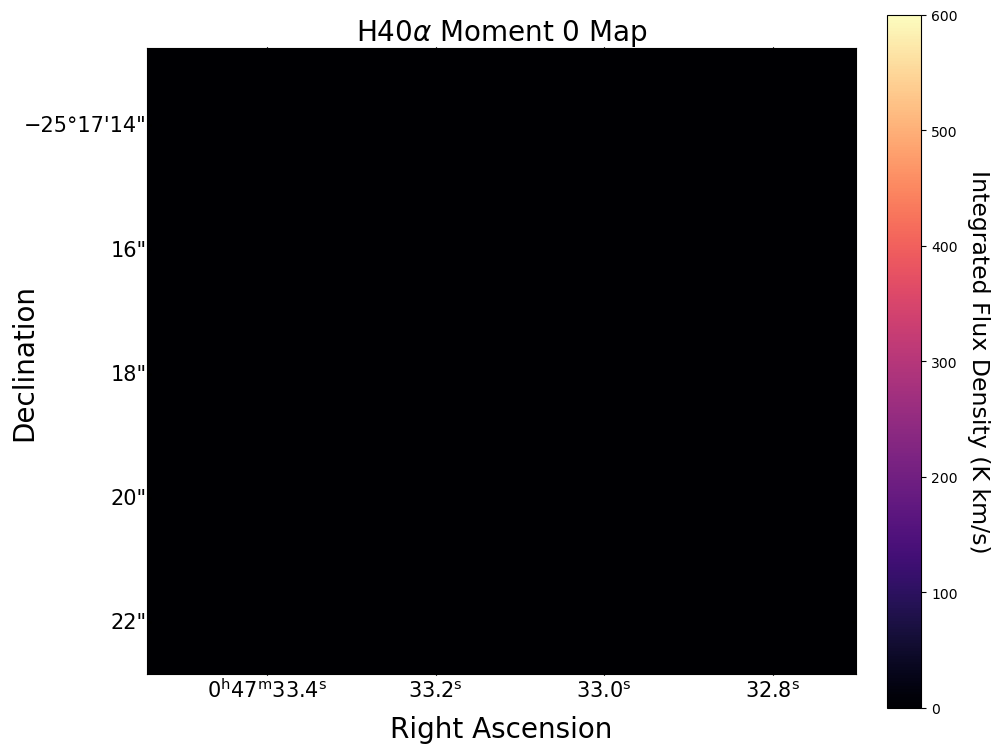

In [178]:
# Location information for arrows (if you wnat to have numbers and arrows) -- if you just want the circles, disregard
Lx  = np.array([283,273,262,222,196,184,183,139,  138,122,74,  47,102, 57])
Ly  = np.array([ 81, 80, 85, 52, 75, 85,155,205,  125,222,180, 191,235,273])
Ldx = np.array([  0,  0,  0,  0,  0,  0,  0,  0,    0,  0,  25,  50,  0,  0])
Ldy = np.array([-13,-15,-15, 20, 17, 15,-16,-20,   18, -18,  0,   0,-20,-15])
Ltx = np.array([ -5, -5, -5, -6, -6, -6, -5, -5,   -6, -10, -22, -23, -10, -10])
Lty = np.array([  3,  3,  3,-15,-15,-15,  3,  2,    -16, 2,  -6,-3,  2,  2])

# Locations of SSCs in NGC 253
sources = np.array(['1','2','3','4','5','6','7','8','9','10','11','12','13','14'])

# Plotting
fig = plt.figure(1,figsize=(10,9))

ax = plt.subplot(1,1,1,projection=moment0.wcs) 
im = ax.imshow(moment0.hdu.data,cmap='magma',origin='lower',vmin=0,vmax=600)

ax.set_title(r'H40$\alpha$ Moment 0 Map', fontsize=20)

RA = ax.coords[0]                                                                  
Dec = ax.coords[1]
RA.set_ticks(size=1)                                                                                      
Dec.set_ticks(size=-3)     

plt.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
plt.ylabel('Declination',fontsize=20,labelpad=0)

ax.tick_params(axis = 'both', which = 'major', labelsize = 15)  
 
cb = fig.colorbar(im, ax=ax, fraction=0.046,pad=0.04)                                      
cb.set_label(label='Integrated Flux Density (K km/s)',fontsize=17,rotation=270,labelpad=23) 
cb.ax.tick_params(which = 'major', labelsize = 10) 

plt.show()

########################### this is the aperture plotting that is important!! ###########################

#for ap in apertures:
#    pixel_aperture = ap.to_pixel(moment0.wcs) # convert the CARTA RA/DEC to image pixels
#    pixel_aperture.visual = {} # you need this to ignore any of the visual settings that would otherwise give you an error (i.e. symsize) as Matplotlib draws the circle
#    pixel_aperture.plot(ax=ax, edgecolor='white',linewidth=0.7, fill=False) # Adds the circle to our plot


############################################################################################################

# Add arrows and numbers
for i,x in enumerate(Lx):
    ax.arrow(x,Ly[i], Ldx[i], Ldy[i],width=0.1,head_width=3,head_length=3,color='white')
    ax.text(x+Ltx[i],Ly[i]+Lty[i],sources[i],fontsize=20,color='white')

############################################################################################################

# Add 30 pc scale bar
D = 3.5e6 * u.pc
L = 30 * u.pc
theta = (L / D) * u.rad
theta_arcsec = theta.to(u.arcsec)
#pixscale = abs(H40alpha_processed_cube.header['CDELT1']) * u.deg
pixscale = abs(H40a_crop_cube.header['CDELT1']) * u.deg
bar_length_pix = (theta_arcsec / pixscale.to(u.arcsec)).value
ax.plot([10, 10 + bar_length_pix],[10, 10],color='white',lw=2)
ax.text(10 + bar_length_pix / 2,12,"30 pc",color='white',ha='center',va='bottom',fontsize=11)

# Add Beam
#beam_radius_pix = (H40alpha_processed_cube.header['BMAJ'] / abs(H40alpha_processed_cube.header['CDELT1'])) / 2.0
beam_radius_pix = (H40a_crop_cube.header['BMAJ'] / abs(H40a_crop_cube.header['CDELT1'])) / 2.0
ny, nx = moment0.shape
beam_x = nx - 15
beam_y = 15
ax.add_patch(matplotlib.patches.Circle((beam_x, beam_y),beam_radius_pix,fill=True,lw=1.2,fc='white',ec='white')) 

plt.show()

# Both methods should give you the same plot, but sometimes its easier to load regions you want to plot in different ways, if possible, CARTA region files are nice to use!